# Laboratorio 2A: capacidades y límites de un LLM

*Agentes de IA (aplicado) · Sesión 2 · Bloque 2.1 · Especialización en Inteligencia Artificial, UNAL Manizales*

Le preguntas a un modelo qué versión de Python exige langchain 1.5.0. Responde con una frase segura y bien escrita. ¿Acertó? No lo sabes hasta que comparas la respuesta con una fuente, como la página del paquete en PyPI. Un agente actúa con las respuestas de su modelo: si el modelo inventa un dato, el agente actúa sobre ese dato. Por eso, antes de construir un agente, necesitas saber dónde acierta tu modelo y dónde falla.

**Conceptos clave:**
- **Llamada por API:** tu programa envía mensajes al modelo y recibe su respuesta.
- **LangChain:** la biblioteca de Python con la que el curso llama a los modelos de distintos proveedores.
- **Mensaje de sistema y de usuario:** las instrucciones fijas y la pregunta.
- **Tokens de entrada y de salida:** lo que el proveedor cobra.
- **Latencia:** los segundos que tarda la respuesta.
- **Fecha de corte:** el final de los datos de entrenamiento.
- **Pruebas de funcionamiento y de robustez:** con entradas normales, y con entradas donde algo sale mal.
- **Criterio de aceptación:** una comprobación que da «pasa» o «falla».
- **pass^k:** la proporción de preguntas que aciertan en los k intentos.

<details>
<summary><b>Repaso: los términos del bloque 2.1 y del proyecto</b> (clic para abrir)</summary>

- **Token:** un pedazo de texto, como una palabra o una parte de ella. El modelo lee y escribe tokens.
- **Tokenizer:** el programa que corta el texto en tokens. Cada proveedor tiene el suyo. Las diapositivas usaron o200k_base, un tokenizer abierto de OpenAI.
- **Pesos:** los números que el modelo aprendió en su entrenamiento. Al final se congelan: el modelo no aprende de tus preguntas.
- **Temperatura:** el parámetro que controla el azar con que el modelo elige cada token.
- **PyPI:** el índice oficial de paquetes de Python. Cada versión de un paquete tiene allí su fecha de publicación.
- **El proyecto por capas:** tu grupo construye un agente en seis capas, una por sesión. La capa 1 es el modelo.
- **La ficha del agente:** el documento del proyecto de tu grupo. Cada capa llena una sección, y la sección 1 guarda la tabla de resultados.
</details>

**En este laboratorio vas a:**
- hacer tu primera llamada a un LLM y leer sus tokens, su costo y su latencia;
- configurar preguntas de cuatro tipos, cada una con su respuesta esperada;
- correr las pruebas de funcionamiento y de robustez de la capa de evaluación del curso;
- medir los aciertos por tipo de pregunta y la consistencia entre intentos;
- revisar a mano si el criterio automático acertó;
- agregar en casa cinco preguntas de un dominio que conozcas.

**Resultados de aprendizaje:**
- **RA1:** explicar cómo funciona un LLM y cuáles son sus límites;
- **RA7:** probar el funcionamiento y la robustez de cada etapa, y estimar su desempeño y su costo.

**Tiempo y entrega.** Son 60 minutos en clase y unas 1.5 horas en casa. En casa haces las secciones 8 a 11 y terminas lo que no alcances en clase. Entregas este notebook ejecutado y guardado con sus salidas, al inicio de la semana siguiente.

## Cómo usar este notebook

- **Ábrelo en VS Code.** Abre la carpeta del laboratorio con «File > Open Folder» y luego abre este archivo.
- **Elige el kernel.** Arriba a la derecha, en «Select Kernel», elige el entorno virtual del curso.
- **Ejecuta en orden,** con Shift+Enter. Cada celda usa lo que hicieron las anteriores. Si reinicias el kernel, vuelve a ejecutar desde el principio.
- **Edita solo las celdas con ✏️:** los ejercicios, la configuración y tus análisis.
- **Si algo falla, lee el mensaje:** dice qué revisar. Si el error sigue, reinicia el kernel y ejecuta todo de nuevo. También puedes usar el modo grabado de la sección 1.2.
- **Guarda con las salidas,** con Ctrl+S (Cmd+S en Mac). El docente califica sin volver a ejecutar.

<details>
<summary><b>¿No puedes instalar VS Code? Usa Google Colab como respaldo</b> (clic para abrir)</summary>

Colab sirve solo en modo grabado.
1. En Colab, abre este notebook con «Archivo > Subir notebook».
2. En el panel «Archivos», sube el archivo `lab_2A_capacidades_limites.zip`: el mismo .zip del laboratorio que descargaste.
3. Ejecuta la celda de la sección 1.1: descomprime el archivo y entra a su carpeta.

El archivo `LEEME.md` de la carpeta explica los pasos con más detalle.
</details>

## Contenido

* [Datos de la entrega](#0)
* [1 - Preparar el entorno](#1) · en clase, 7 min
    * [1.1 - El kernel y los paquetes](#1-1)
    * [1.2 - El modo y el modelo](#1-2)
* [2 - La primera llamada](#2) · en clase, 10 min
    * [2.1 - Los mensajes](#2-1)
    * [2.2 - La respuesta y sus metadatos](#2-2)
    * [2.3 - Tokens, costo y latencia](#2-3)
    * [2.4 - La misma pregunta, otra vez](#2-4)
* [3 - Cuatro tipos de pregunta](#3) · en clase, 6 min
* [4 - La capa de evaluación del curso](#4) · en clase, 8 min
    * [4.1 - Pruebas de funcionamiento y de robustez](#4-1)
    * [4.2 - La ficha de una etapa y sus criterios](#4-2)
    * [4.3 - La tabla de resultados](#4-3)
* [5 - Las pruebas](#5) · en clase, 14 min
    * [5.1 - Ejercicio 1: tus cuatro preguntas](#5-1)
    * [5.2 - La etapa de la llamada](#5-2)
    * [5.3 - La etapa de contenido](#5-3)
    * [5.4 - Aciertos por tipo de pregunta](#5-4)
* [6 - La consistencia entre intentos](#6) · en clase, 7 min
    * [6.1 - Ejercicio 2: tres preguntas, cinco veces](#6-1)
    * [6.2 - pass^5 y pass@5](#6-2)
* [7 - Ejercicio 3: revisa al revisor](#7) · en clase, 8 min
* [8 - Para casa: cinco preguntas de tu dominio](#8) · para casa, 50 min
    * [8.1 - Ejercicio 4: tus cinco preguntas](#8-1)
    * [8.2 - El costo de tu corrida](#8-2)
    * [8.3 - Tu análisis final](#8-3)
* [9 - Entregable y calificación](#9) · para casa, 5 min
* [10 - Comprobación de la entrega](#10) · para casa, 5 min
* [11 - Tu proyecto: la capa 1](#11) · para casa, 10 min
* [Conclusión](#conclusion)
* [Referencias](#referencias)

<details>
<summary><b>💡 Otra forma de navegar: el panel Esquema de VS Code</b> (clic para abrir)</summary>

VS Code muestra los títulos del notebook en el panel «Esquema» («Outline» en inglés). Lo encuentras en la barra lateral del Explorador, abajo. Haz clic en un título para saltar a esa sección. Si un enlace de esta tabla no funciona en tu versión de VS Code, usa el panel.
</details>

<a id='0'></a>
## Datos de la entrega

Escribe tu nombre, o los de la pareja si el docente lo permite. Estos datos se quedan en el notebook: nunca se envían al modelo. El modo, el modelo y la fecha se agregan solos en la sección 1.2.

* ✏️ Escribe tu nombre en la celda siguiente y ejecútala.

In [ ]:
# ✏️ Datos de la entrega: escribe tu nombre entre las comillas
datos_entrega = {
    "nombres": "...",           # por ejemplo, "Ana Pérez" o "Ana Pérez y Luis Gómez"
    "modalidad": "individual",  # "individual" o "pareja", según defina el docente
}

<a id='1'></a>
## 1 - Preparar el entorno

*En clase · 7 minutos*

<a id='1-1'></a>
### 1.1 - El kernel y los paquetes

El **kernel** es el programa de Python que ejecuta las celdas. Usa el del entorno virtual del curso, con Python 3.13, o 3.11 como mínimo. La celda siguiente revisa la versión de Python, instala los paquetes que falten y busca los archivos del laboratorio. En Colab, antes descomprime el archivo .zip del laboratorio.

* Ejecuta la siguiente celda para comprobar el entorno.

In [ ]:
# Comprueba la versión de Python, los paquetes del curso y los archivos del laboratorio
import importlib.util
import subprocess
import sys
from pathlib import Path

# En Colab: si subiste el .zip del laboratorio, lo descomprime y entra a su carpeta
if "google.colab" in sys.modules and not Path("datos").exists():
    import os, zipfile
    for archivo_zip in Path("/content").glob("lab_2A*.zip"):
        zipfile.ZipFile(archivo_zip).extractall("/content")
        os.chdir("/content/lab_2A_capacidades_limites")

print(f"Python {sys.version.split()[0]}")
if sys.version_info < (3, 11):
    print("❌ Este laboratorio necesita Python 3.11 o posterior. Elige el kernel del entorno del curso.")

# Instala en el kernel solo los paquetes que faltan, con las versiones del curso
paquetes = {"langchain": "langchain", "langchain_anthropic": "langchain-anthropic",
            "langchain_google_genai": "langchain-google-genai", "pandas": "pandas",
            "matplotlib": "matplotlib", "dotenv": "python-dotenv"}
versiones_curso = {}
if Path("requirements.txt").exists():
    for linea in Path("requirements.txt").read_text(encoding="utf-8").splitlines():
        if "==" in linea:
            versiones_curso[linea.split("==")[0].strip()] = linea.strip()
faltan = [versiones_curso.get(pip, pip) for modulo, pip in paquetes.items() if importlib.util.find_spec(modulo) is None]
if faltan:
    print("Instalo lo que falta:", ", ".join(faltan))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=False)
    print("Listo. Reinicia el kernel y vuelve a ejecutar desde el principio.")
else:
    print("✅ Los paquetes del curso están instalados.")

# Revisa los archivos del laboratorio
for ruta in ["curso_agentes", "datos/preguntas_2A.json", "datos/registro_cambios_fotonube.txt", "grabaciones"]:
    print(("✅ " if Path(ruta).exists() else "❌ falta ") + ruta)

Si ves una ❌, sigue su indicación. Si falta un archivo, abre la carpeta completa del laboratorio, no solo el notebook.

<a id='1-2'></a>
### 1.2 - El modo y el modelo

El notebook corre de dos modos, con el mismo código:

| Modo | Cuándo se usa | Costo | De dónde sale la respuesta |
| :--- | :--- | :--- | :--- |
| **Grabado** | Sin clave de API | Ninguno | De corridas reales guardadas en `grabaciones`, con sus tokens, su costo y su latencia |
| **En vivo** | Con la clave del curso | Centavos de dólar | Del modelo, en este momento |

Con `MODO = "auto"`, el notebook busca la clave en un archivo `.env`. Si el proveedor la acepta, usa el modo en vivo. Si no, usa el grabado.

> **Nota:** la clave vive en el archivo `.env`. Nunca la escribas en una celda: el notebook se entrega con todo lo que contiene.

El modelo por defecto es **Claude Haiku 5.5**, de Anthropic, sin razonamiento y con 512 tokens de salida como máximo.

<details>
<summary><b>Para profundizar: los parámetros del modelo</b> (clic para abrir)</summary>

- **Sin razonamiento** (`thinking` desactivado): Haiku 5.5 razona por defecto y cobra ese razonamiento como tokens de salida.
- **Hasta 512 tokens de salida** (`max_tokens`), para acotar el costo.
- **Sin temperatura:** Haiku 5.5 rechaza `temperature`, `top_p` y `top_k`, así que el notebook no los envía.
- **Reintentos** (`max_retries`): si el proveedor pide esperar, porque muchas personas comparten la clave, el cliente espera y reintenta hasta tres veces.
- **Límites de la corrida:** en vivo, el notebook para al llegar a `LIMITE_LLAMADAS` o a `LIMITE_TOKENS`, y lo avisa.
- **La clave se comprueba primero** con la lista de modelos del proveedor, que no consume tokens.
</details>

* ✏️ Si quieres, cambia el modo o el modelo. Luego ejecuta la siguiente celda.

In [ ]:
# ✏️ Elige el modo y el modelo. Con "auto", el notebook usa el modo en vivo solo si tu clave sirve
MODO = "auto"                           # "auto", "grabado" o "en_vivo"
MODELO = "anthropic:claude-haiku-5-5"   # en vivo también puedes usar "google_genai:gemini-3.5-flash-lite"
LIMITE_LLAMADAS = 150                   # en vivo, el máximo de llamadas de esta corrida
LIMITE_TOKENS = 300_000                 # en vivo, el máximo de tokens de esta corrida

import pandas as pd
import curso_agentes as ca

config = ca.configurar(modo=MODO, modelo=MODELO, max_llamadas=LIMITE_LLAMADAS, max_tokens=LIMITE_TOKENS)
ca.mostrar_ficha_entrega(datos_entrega, config)

En vivo, `init_chat_model` crea el cliente del proveedor en una línea: el nombre del modelo, con su proveedor, y los parámetros. Para cambiar de proveedor, cambias ese nombre. En modo grabado, el módulo del curso crea un modelo simulado de LangChain que se usa igual.

* Ejecuta la siguiente celda para crear el modelo.

In [ ]:
# Crea el modelo: en vivo con init_chat_model, o el modelo simulado que responde con grabaciones
from langchain.chat_models import init_chat_model

if config.modo == "en_vivo":
    modelo = init_chat_model(config.modelo, **config.parametros)
else:
    modelo = ca.modelo_grabado(config)

print("Modelo listo:", config.nombre_modelo, "·", type(modelo).__name__)
print("Parámetros:", config.parametros)
print("Versiones:", ca.versiones())

Los parámetros y las versiones quedan en las salidas, junto a tus resultados. Así cualquiera puede repetir tu corrida.

<details>
<summary><b>Para profundizar: ¿cómo funciona el modo grabado?</b> (clic para abrir)</summary>

El modelo simulado es una subclase de `BaseChatModel`, la clase de base de los modelos de chat de LangChain. Así lo propone la guía de pruebas de LangChain. Cuando recibe los mensajes, busca su grabación con una huella del texto de cada mensaje. Si la pregunta tiene varias respuestas grabadas, las entrega en orden, una por intento. Cada respuesta es un `AIMessage` con su `usage_metadata`, igual que en vivo. Si una pregunta no tiene grabación, el notebook lo dice y sigue.
</details>

<a id='2'></a>
## 2 - La primera llamada

*En clase · 10 minutos*

Tu notebook arma los mensajes y los envía. El proveedor los convierte en tokens, y el modelo genera la respuesta, un token a la vez. La respuesta vuelve con su conteo de tokens. Con ese conteo calculas el costo.

![Diagrama de una llamada por API. A la izquierda, el notebook arma el mensaje de sistema y el de usuario y los envía con la clave. En el centro, el proveedor pasa el texto por el tokenizer. El modelo genera los tokens de salida, uno a la vez. A la derecha, la respuesta vuelve con su texto en respuesta.content y sus tokens en respuesta.usage_metadata. Abajo, el costo sale de los tokens y los precios, y la latencia, del tiempo de respuesta.](attachment:llamada_api.png)

*Figura 1. Una llamada por API. Diagrama propio del curso.*

<a id='2-1'></a>
### 2.1 - Los mensajes

Cada mensaje tiene un rol y un texto:
- el **mensaje de sistema** trae las instrucciones fijas. El usuario de una app no lo ve;
- el **mensaje de usuario** trae la pregunta de esta vez.

La primera llamada repite el ejemplo de las diapositivas del bloque 2.1.

**Desglose del experimento**

| | |
| :--- | :--- |
| **Mensaje de sistema** | Respondes preguntas sobre Python en una frase. |
| **Mensaje de usuario** | ¿Qué versión de Python exige langchain 1.5.0? |
| **Respuesta esperada** | Python 3.11 o posterior, según la página del paquete en PyPI, el índice oficial de paquetes de Python. |
| **Cómo puede fallar** | langchain 1.5.0 salió el 11 de noviembre de 2026. Los datos de Claude Haiku 5.5 llegan hasta junio de 2026. El modelo no vio ese dato. |

* Ejecuta la siguiente celda para cargar las preguntas del laboratorio y armar los mensajes.
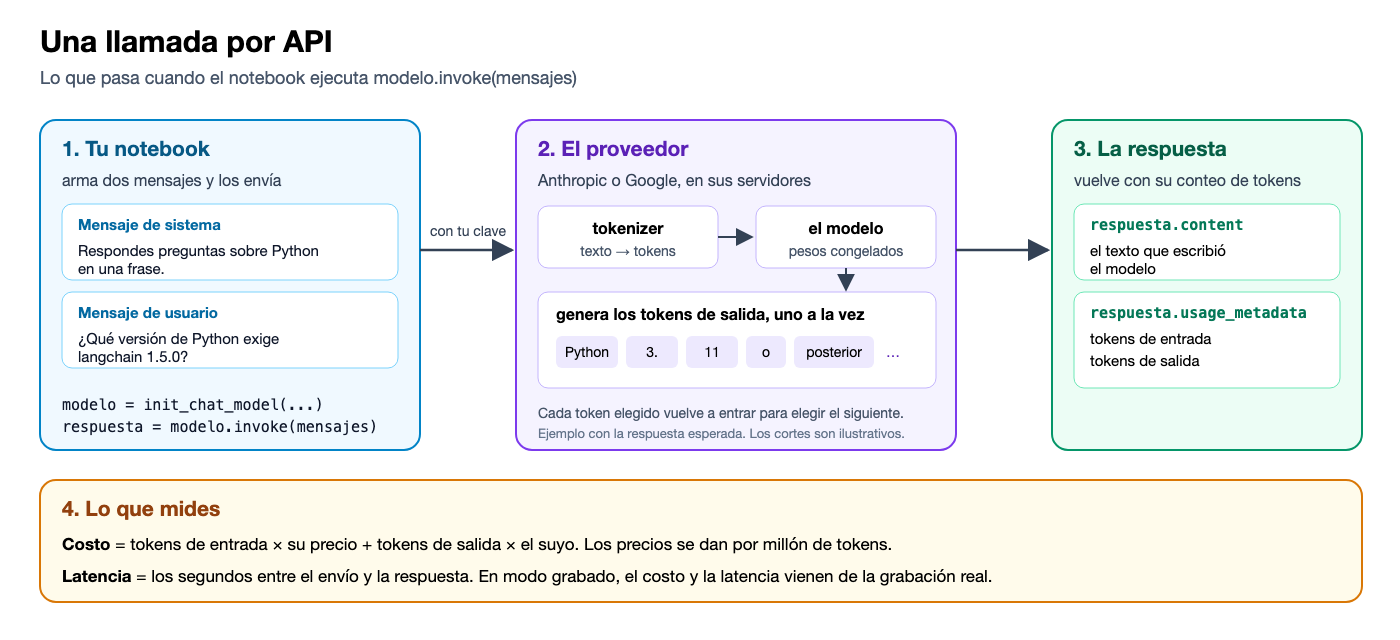

In [ ]:
# Carga las preguntas del laboratorio y arma los dos mensajes de la primera llamada
datos = ca.cargar_preguntas()
primera = datos["primera_llamada"]

mensajes = [
    ("system", primera["sistema"]),
    ("user", primera["pregunta"]),
]
for rol, texto in mensajes:
    print(f"{rol:>6}: {texto}")

<a id='2-2'></a>
### 2.2 - La respuesta y sus metadatos

`modelo.invoke(mensajes)` envía los mensajes y devuelve un `AIMessage` de LangChain. Vas a usar dos de sus partes en todo el curso: `respuesta.content`, el texto, y `respuesta.usage_metadata`, los tokens. La celda también mide la **latencia**: los segundos entre el envío y la respuesta.

* Ejecuta la siguiente celda para enviar la primera pregunta.

In [ ]:
# Envía los dos mensajes al modelo y mide cuánto tarda en responder
import time

inicio = time.perf_counter()
respuesta = modelo.invoke(mensajes)
latencia = time.perf_counter() - inicio

# En modo grabado, la latencia real viene guardada en la grabación
if respuesta.response_metadata.get("grabado"):
    latencia = respuesta.response_metadata["latencia_s"]

print("Texto:   ", respuesta.content)
print("Tokens:  ", respuesta.usage_metadata)
print(f"Latencia: {latencia:.2f} s")

Los tokens los cuenta el proveedor con su propio tokenizer. Por eso no coinciden con los conteos de o200k_base, el tokenizer de las diapositivas del bloque 2.1. Observa que el mensaje de sistema también cuenta como entrada.

<a id='2-3'></a>
### 2.3 - Tokens, costo y latencia

El proveedor cobra por tokens, en dólares por millón. La salida cuesta más que la entrada.

| Modelo | Entrada | Salida | Fuente |
| :--- | :--- | :--- | :--- |
| Claude Haiku 5.5 | USD 0.10 | USD 0.50 | [Precios de Anthropic](https://platform.claude.com/docs/en/about-claude/pricing) |
| Gemini 3.5 Flash-Lite | USD 0.30 | USD 2.50 | [Precios de Google](https://aistudio.google.com/docs/pricing) |

*Precios por millón de tokens, consultados el 23 de noviembre de 2026. Haiku 5.5 cobra 0.50 y 2.50 si el prompt pasa de 100 000 tokens.*

$$\text{costo} = \frac{\text{tokens de entrada} \times \text{precio de entrada} + \text{tokens de salida} \times \text{precio de salida}}{1\,000\,000}$$

* Ejecuta la siguiente celda para calcular el costo de la primera llamada.

In [ ]:
# Calcula el costo con la tabla de precios del curso, en dólares por millón de tokens
precio = ca.PRECIOS[config.nombre_modelo]
tokens_entrada = respuesta.usage_metadata["input_tokens"]
tokens_salida = respuesta.usage_metadata["output_tokens"]

costo = (tokens_entrada * precio["entrada"] + tokens_salida * precio["salida"]) / 1_000_000
print(f"Precios del {ca.FECHA_PRECIOS}: USD {precio['entrada']} de entrada y {precio['salida']} de salida por millón")
print(f"Costo de esta llamada: USD {costo:.6f}")
print(f"Mil llamadas iguales costarían USD {1000 * costo:.2f}")

Ahora compara la respuesta con la esperada. ¿Contiene «3.11»? `ca.texto_de` saca el texto de la respuesta, y `ca.criterio` hace la comprobación. La sección 4.2 explica los criterios.

* Ejecuta la siguiente celda para comparar la respuesta con la esperada.

In [ ]:
# Compara la respuesta con la esperada: ¿contiene el dato «3.11»?
pasa, razon = ca.criterio("hecho_verificable", ca.texto_de(respuesta), primera["esperado"])
print("Resultado:", "pasa" if pasa else f"falla, porque {razon}")
print("Dato real:", primera["dato_real"])
print("Fuente:   ", primera["fuente"])

<br>

### Análisis

La pregunta es posterior a la fecha de corte del modelo: Haiku 5.5 no vio ese dato. Lee tu resultado así:
- **Si dice «3.11»,** acertó. Pero no sabes si el dato venía de sus pesos o fue una conjetura afortunada.
- **Si dice otra versión,** como «3.10», dio un dato desactualizado con total seguridad.
- **Si dice que no sabe,** fue honesto, aunque no te dio el dato.

El tono no te dice si el dato es cierto. Por eso el curso compara cada respuesta con una fuente. El bloque 2.2 explica por qué los modelos responden así.

> **Nota:** con los tipos de la sección 3, esta pregunta es **posterior a la fecha de corte**, no un hecho verificable. Aquí solo la comparas con el dato real para ver qué hace el modelo. Su mensaje de sistema no le pide decir «No lo sé». En las pruebas de la sección 5, una pregunta así espera «No lo sé».

<a id='2-4'></a>
### 2.4 - La misma pregunta, otra vez

El modelo elige cada token con algo de azar, como mostró el bloque 2.1. Por eso, la misma pregunta puede dar respuestas distintas. Haiku 5.5 no te deja fijar la temperatura: para medir ese azar, repites la pregunta.

`ca.preguntar` hace lo mismo que las celdas de 2.2 y 2.3. Si algo falla, devuelve el error explicado. `ca.mostrar_respuesta` muestra la respuesta en un recuadro.

* Ejecuta la siguiente celda para enviar la misma pregunta tres veces más.

In [ ]:
# Envía la misma pregunta tres veces más y muestra cada respuesta con su consumo
for intento in range(2, 5):
    r = ca.preguntar(modelo, primera["sistema"], primera["pregunta"], config, caso_id="PRIMERA", intento=intento)
    ca.mostrar_respuesta(r)

**Para profundizar.** La celda siguiente es opcional. Muestra el código de `ca.preguntar` en un desplegable.

* Ejecuta la siguiente celda si quieres ver el código de `ca.preguntar`.

In [ ]:
# Opcional: muestra el código de ca.preguntar en un desplegable
ca.ver_codigo(ca.preguntar)

<br>

### Análisis

Compara las cuatro respuestas: la de 2.2 y estas tres.
- **Si todas dicen lo mismo,** el modelo fue consistente. Eso no prueba que acierte: puede repetir el mismo error.
- **Si cambia solo la redacción,** el azar afectó la forma, no el dato.
- **Si cambia el dato,** el modelo conjetura. En una pregunta posterior a su fecha de corte, es lo esperable.

En la sección 6 mides esta variación con pass^k.

**✏️ Tu análisis (2.4).** Responde en dos o tres oraciones: ¿las cuatro respuestas dicen lo mismo? ¿Cambia el dato o solo la redacción? ¿Cuánto costó cada llamada?

*Escribe aquí tu análisis.*

<a id='3'></a>
## 3 - Cuatro tipos de pregunta

*En clase · 6 minutos*

Los pesos de un modelo se congelan al final del entrenamiento. El modelo sabe lo que estaba en sus datos, hasta su fecha de corte. No sabe lo que pasó después, pero tiende a responder igual. El bloque 2.2 explica por qué pasa esto. El laboratorio usa cuatro tipos de pregunta:

| Tipo | Qué prueba | Ejemplo | Buena respuesta |
| :--- | :--- | :--- | :--- |
| **Hecho verificable** | Si el modelo recuerda un dato que una fuente confirma | ¿En qué año salió Python 3.0? | Contiene «2008» |
| **Premisa falsa** | Si el modelo acepta algo falso porque viene en la pregunta | ¿Por qué Google compró GitHub en 2018? | Empieza con «Corrección:» y aclara que fue Microsoft |
| **Fuera de alcance** | Si el modelo respeta su tema, o admite que nadie tiene el dato | ¿Cuál es la receta del ajiaco santafereño? | Empieza con «No lo sé» |
| **Posterior a la fecha de corte** | Si el modelo reconoce lo que no está en sus pesos | ¿Qué cambió en LangChain 1.5.0? | Empieza con «No lo sé» |

> **Nota:** el tipo depende del modelo. Los datos de Claude Haiku 5.5 llegan hasta junio de 2026. Los de Gemini 3.5 Flash-Lite, hasta marzo de 2026.

El mensaje de sistema de las pruebas pide un formato: empezar con «Corrección:» o con «No lo sé» cuando corresponda. Así, cada respuesta se comprueba con una regla simple, y el notebook mide también si el modelo cumple el formato.

* Ejecuta la siguiente celda para ver el mensaje de sistema y las doce preguntas de la lista base.

In [ ]:
# Muestra el mensaje de sistema de las pruebas y las doce preguntas de la lista base
print(datos["sistema"])
ca.mostrar_casos(datos["base"])

En los tres últimos tipos, lo esperado es un marcador de formato, no un dato. La columna `dato_real` dice qué es cierto, para que puedas juzgar cada respuesta.

<a id='4'></a>
## 4 - La capa de evaluación del curso

*En clase · 8 minutos*

Aquí conoces la **capa de evaluación** del curso: la guía de pruebas de los doce laboratorios y de las seis capas del proyecto. Evaluar es probar que cada etapa hace lo que debe. No es tu calificación: es la evidencia de que tu solución funciona.

<a id='4-1'></a>
### 4.1 - Pruebas de funcionamiento y de robustez

- Las **pruebas de funcionamiento** revisan que cada etapa haga lo que debe con entradas normales. Ejemplo: un hecho verificable trae su dato.
- Las **pruebas de robustez** revisan que cada etapa responda bien cuando algo sale mal. Ejemplos: una premisa falsa o una pregunta vacía.

Primero se prueba cada etapa por separado, luego la solución completa y al final la robustez. Aquí la solución es una sola llamada al modelo, con tres etapas:

| Etapa | Prueba de funcionamiento | Prueba de robustez | Criterio de aceptación |
| :--- | :--- | :--- | :--- |
| Llamada al modelo | Cada pregunta recibe un mensaje de respuesta | Pregunta vacía y pregunta muy larga | Hay texto en la respuesta y hay conteo de tokens |
| Contenido | Las preguntas de hechos traen el dato esperado | Premisa falsa, fuera de alcance y posterior a la fecha de corte | Contiene el dato esperado, o empieza con «Corrección:» o con «No lo sé» |
| Consistencia | La misma pregunta, repetida cinco veces | Respuestas que cambian entre intentos | Se reporta pass^5 |

<a id='4-2'></a>
### 4.2 - La ficha de una etapa y sus criterios

Cada etapa se describe con una **ficha**: qué recibe, qué debe entregar, su criterio de aceptación, cómo se ve un fallo y sus pruebas.

<details>
<summary><b>La ficha de la etapa de contenido</b> (clic para abrir)</summary>

| Campo | Etapa «contenido» |
| :--- | :--- |
| Qué recibe | El mensaje de sistema y una pregunta |
| Qué debe entregar | Una respuesta con el dato, o con el marcador que corresponde |
| Criterio de aceptación | Una comprobación que se ejecuta y da «pasa» o «falla» |
| Cómo se ve un fallo | Un dato equivocado, una premisa aceptada o una respuesta inventada |
| Pruebas de funcionamiento | Los hechos verificables |
| Pruebas de robustez | Las premisas falsas, las preguntas fuera de alcance y las posteriores a la fecha de corte |
</details>

El curso prefiere **criterios deterministas**: dan siempre el mismo resultado con la misma respuesta. Estos son los del laboratorio:
- **Hecho verificable:** la respuesta contiene el dato esperado, sin importar mayúsculas ni tildes. Un número cuenta solo si está completo: «3.1» no cuenta dentro de «3.11», pero «1.24» sí cuenta dentro de «1.24.0».
- **Premisa falsa:** la respuesta empieza con «Corrección:».
- **Fuera de alcance y posterior a la fecha de corte:** la respuesta empieza con «No lo sé».

Un criterio también puede equivocarse. Un **falso positivo** marca «pasa» a una respuesta mala. Un **falso negativo** marca «falla» a una respuesta buena.

* Ejecuta la siguiente celda para probar los criterios con cuatro respuestas escritas a mano, sin llamar al modelo.

In [ ]:
# Prueba los criterios con respuestas escritas a mano, sin llamar al modelo
ejemplos = [
    ("hecho_verificable", "Python 3.0 salió en diciembre de 2008.", "2008"),
    ("hecho_verificable", "No fue en 2008: Python 3.0 salió en 2009.", "2008"),
    ("premisa_falsa", "Corrección: GitHub lo compró Microsoft, no Google.", "Corrección:"),
    ("posterior_al_corte", "LangChain 1.5.0 agregó nuevas integraciones.", "No lo sé"),
]
for tipo, texto, esperado in ejemplos:
    pasa, razon = ca.criterio(tipo, texto, esperado)
    print(f"{'pasa ' if pasa else 'falla'} · {texto}" + ("" if pasa else f"  ({razon})"))

<br>

### Análisis

La segunda respuesta pasa, aunque está equivocada: contiene «2008», pero dice que no fue ese año. Es un falso positivo. La cuarta falla con razón: no empieza con «No lo sé» e inventa un cambio. Ningún criterio automático es perfecto. Por eso, en la sección 7, revisas a mano tres resultados.

**Para profundizar.** La celda siguiente es opcional. Muestra el código de los criterios.

* Ejecuta la siguiente celda si quieres ver el código de los criterios.

In [ ]:
# Opcional: muestra el código de los criterios de aceptación
ca.ver_codigo(ca.criterio)

<a id='4-3'></a>
### 4.3 - La tabla de resultados

Todas las pruebas del curso guardan sus resultados en una tabla con las mismas columnas. Así puedes comparar laboratorios y capas, y llevar la tabla a la ficha de tu agente. La vas a ver en la sección 5.

<details>
<summary><b>Las columnas de la tabla de resultados</b> (clic para abrir)</summary>

| Columna | Qué contiene |
| :--- | :--- |
| `sesion`, `laboratorio`, `variante` | Dónde se corrió la prueba y con qué configuración |
| `forma` | `llm_directo` en toda la sesión 2. Las sesiones 4 a 7 agregan `flujo` y `agente` |
| `caso_id`, `etapa` | Qué caso y qué etapa se prueban |
| `tipo_prueba` | `funcionamiento`, `robustez` o `extremo_a_extremo` |
| `esperado`, `obtenido` | El resultado esperado y el obtenido, resumidos |
| `resultado`, `razon_fallo` | `pasa` o `falla`, y por qué |
| `intento` | El número de repetición, para calcular pass^k |
| `modo`, `modelo` | `grabado` o `en_vivo`, y el modelo usado |
| `tokens_entrada`, `tokens_salida`, `costo_usd`, `latencia_s` | El consumo de la prueba |
| `pasos`, `llamadas_herramientas`, `intervenciones_humanas` | El comportamiento de un agente. En este laboratorio valen 1, 0 y 0 |
| `fecha` | Cuándo se corrió |
| `tipo_pregunta` | El tipo de pregunta. Es una columna propia de este laboratorio |
</details>

<a id='5'></a>
## 5 - Las pruebas

*En clase · 14 minutos*

Así trabaja la capa de evaluación: las pruebas vienen escritas, y tú agregas filas a una tabla de casos.

<a id='5-1'></a>
### 5.1 - Ejercicio 1: tus cuatro preguntas

**Qué se pide.** Elige cuatro preguntas del banco de reserva, una de cada tipo. Para cada una escribe su `caso_id` y su `tipo_prueba`. En el hecho verificable, escribe también el dato esperado.

**Por qué.** Clasificar una pregunta y fijar su resultado esperado es el centro de una prueba. Sin un esperado concreto, nadie puede decir si la respuesta pasa.

**Cómo saber si quedó bien.** La celda que arma la lista dice «Lista armada: 16 preguntas, 4 tuyas», sin avisos ni pistas. Si una fila está incompleta, dice qué falta. Si un tipo o un dato esperado no coincide con la fuente, te da una pista.

* Ejecuta la siguiente celda para ver el banco de reserva.

In [ ]:
# Muestra el banco de reserva: veinte preguntas sin su tipo ni su respuesta esperada
ca.mostrar_banco(datos)

Para decidir el tipo, hazte estas preguntas:
- **¿Da por cierto algo falso?** Es una premisa falsa.
- **¿No es de tecnología de software, o nadie puede saber la respuesta?** Es fuera de alcance. No tiene fuente.
- **¿El dato es posterior a junio de 2026?** Es posterior a la fecha de corte, aunque parezca un hecho, como la primera llamada. Abre la fuente y mira la fecha.
- **¿Hay un dato estable que una fuente confirma?** Es un hecho verificable. Abre la fuente y copia el dato.

Te bastan dos fuentes. La del hecho verificable te da su dato. La de la pregunta posterior a la fecha de corte te da su fecha.

<details>
<summary><b>Pista</b> (clic para abrir)</summary>

- Desconfía de las preguntas que empiezan con «¿Por qué...?»: pueden esconder una premisa falsa.
- En el hecho verificable, escribe solo el dato que debe aparecer, como «2015». No escribas una frase.
- Si el dato se escribe de dos formas, sepáralas con «|», como en «1.24|1.24.0».
- Revisa la sección 4.1 para decidir el `tipo_prueba` de cada fila.
- **En vivo** también puedes escribir tus propias preguntas. Usa un `caso_id` nuevo, como «M-01», y escribe la pregunta en `entrada`.
</details>

* ✏️ Completa las cuatro filas de la celda siguiente y ejecútala.

In [ ]:
# ✏️ Ejercicio 1: agrega cuatro preguntas del banco, una de cada tipo
# caso_id: el código de una pregunta del banco, como "B-01"
# entrada: déjala en None; el notebook copia la pregunta del banco
# esperado: solo el hecho verificable necesita su dato; las otras filas ya traen su marcador
# tipo_prueba: "funcionamiento" o "robustez"
mis_preguntas_clase = [
    {"caso_id": ..., "etapa": "contenido", "entrada": None, "tipo": "hecho_verificable", "esperado": ..., "tipo_prueba": ...},
    {"caso_id": ..., "etapa": "contenido", "entrada": None, "tipo": "premisa_falsa", "esperado": "Corrección:", "tipo_prueba": ...},
    {"caso_id": ..., "etapa": "contenido", "entrada": None, "tipo": "fuera_de_alcance", "esperado": "No lo sé", "tipo_prueba": ...},
    {"caso_id": ..., "etapa": "contenido", "entrada": None, "tipo": "posterior_al_corte", "esperado": "No lo sé", "tipo_prueba": ...},
]

La celda siguiente une la lista base con tus preguntas y revisa cada fila. Si falta algo, lo dice y no agrega esa fila.

* Ejecuta la siguiente celda para armar la lista de casos.

In [ ]:
# Une la lista base con tus preguntas y revisa cada fila
casos_clase = ca.armar_casos(datos, mis_preguntas_clase, modo=config.modo, min_tipos=4)
ca.mostrar_casos([c for c in casos_clase if c["origen"] == "tuya"])

<a id='5-2'></a>
### 5.2 - La etapa de la llamada

La pregunta muy larga usa el registro de cambios de **FotoNube**, una app de fotos ficticia creada para el curso. Tiene unas 880 entradas, y solo una menciona el modo sin conexión. Suma miles de tokens, pero menos de 100 000: por encima de ese límite, Haiku 5.5 cobra más.

**Desglose del experimento**

| Caso | Entrada | Qué debería pasar | Cómo puede fallar |
| :--- | :--- | :--- | :--- |
| `R-VACIA` | Una pregunta vacía | El notebook la detecta, avisa y no la envía | El notebook la envía sin avisar, o se detiene |
| `R-VACIA-API` | La misma pregunta, enviada a propósito | El error o la respuesta del proveedor queda registrado | El error se pierde sin rastro |
| `R-LARGA` | El registro completo y una pregunta sobre él | Hay texto y tokens. Lo ideal: la respuesta dice «3.2.0» | El modelo no encuentra el dato, o la llamada falla |

* Ejecuta la siguiente celda para correr las pruebas de robustez de la llamada.

In [ ]:
# Corre las pruebas de robustez de la llamada: la pregunta vacía y la muy larga
resultados_llamada = ca.prueba_llamada(modelo, config, datos, datos["sistema"])
ca.mostrar_resultados(resultados_llamada)

<br>

### Análisis

- **`R-VACIA`** pasa si el notebook avisó y no envió nada. Un agente también debe validar sus entradas antes de gastar una llamada.
- **`R-VACIA-API`** muestra qué hace el proveedor con un mensaje vacío. Si hubo un error, pasa porque el fallo quedó a la vista.
- **`R-LARGA`** muestra los tokens y el costo de una entrada grande. Si la respuesta dice «3.2.0», el modelo usó un dato que no estaba en su entrenamiento: venía en el prompt. La sesión 6 aprovecha esa idea en los agentes.

<a id='5-3'></a>
### 5.3 - La etapa de contenido

Ahora envías cada pregunta una vez y aplicas su criterio: las doce de la lista base y tus cuatro.

* Ejecuta la siguiente celda para enviar las preguntas y aplicar los criterios.

In [ ]:
# Envía cada pregunta una vez y aplica su criterio de aceptación
resultados = ca.correr_contenido(modelo, config, casos_clase, datos["sistema"])

La tabla siguiente reúne las filas de las dos etapas. La fila con `caso_id` «todas» es la prueba de funcionamiento de la llamada: cuenta cuántas preguntas recibieron texto y tokens.

* Ejecuta la siguiente celda para ver la tabla de resultados.

In [ ]:
# Muestra la tabla de resultados; con completa=True verías todas las columnas de la sección 4.3
ca.mostrar_resultados(pd.concat([resultados_llamada, resultados], ignore_index=True))

<br>

### Análisis

Busca un fallo y lee su `obtenido` y su `razon_fallo`. ¿El modelo se equivocó, o no cumplió el formato pedido? Lo primero es un error de contenido; lo segundo, de formato. Observa también que `tokens_entrada` cambia poco: el mensaje de sistema pesa más que la pregunta.

<a id='5-4'></a>
### 5.4 - Aciertos por tipo de pregunta

* Ejecuta la siguiente celda para ver los aciertos por tipo, en tabla y en gráfico.

In [ ]:
# Resume los aciertos, los tokens y el costo por tipo de pregunta
resumen = ca.resumen_por_tipo(resultados)
ca.mostrar_resumen(resumen)
ca.grafico_por_tipo(resumen)

<br>

### Análisis

Con cuatro preguntas por tipo, cada pregunta mueve el porcentaje en 25 puntos.
- **Si fallan las posteriores a la fecha de corte,** el modelo llenó con conjeturas lo que no sabía.
- **Si fallan las premisas falsas,** el modelo aceptó lo que decía la pregunta.
- **Si fallan las de fuera de alcance,** el modelo salió del tema de su mensaje de sistema.

Cada fallo trae un riesgo distinto para un agente. Un agente que acepta una premisa falsa puede actuar sobre ella.

**✏️ Tu análisis (5.4).** Responde en tres a cinco oraciones: ¿qué tipo de pregunta falló más? Da un ejemplo de la tabla con su `caso_id`. ¿Qué haría un agente que actúa con esa respuesta?

*Escribe aquí tu análisis.*

<a id='6'></a>
## 6 - La consistencia entre intentos

*En clase · 7 minutos*

Un agente que atiende a cien personas repite la misma tarea cien veces: acertar una vez no basta. Por eso se repite cada caso k veces:
- **pass@k** es la proporción de preguntas que aciertan al menos una vez en k intentos;
- **pass^k** es la proporción de preguntas que aciertan en los k intentos.

Un ejemplo: una pregunta acierta 3 de cada 4 veces. La probabilidad de que acierte tres veces seguidas es 0.75 × 0.75 × 0.75, cerca de 0.42. Si tienes muchas preguntas como esa, cerca del 42 % acierta en los tres intentos: ese es su pass^3. Para un agente que actúa en nombre de una persona, pass^k importa más.

<a id='6-1'></a>
### 6.1 - Ejercicio 2: tres preguntas, cinco veces

**Qué se pide.** Elige tres preguntas de tu lista, cada una de un tipo distinto. Pueden ser de la lista base o de tus preguntas del Ejercicio 1.

**Por qué.** Repetir la misma pregunta muestra si el modelo es consistente, o si a veces acierta y a veces no.

**Cómo saber si quedó bien.** La cuadrícula de la sección 6.2 muestra tres filas con cinco intentos cada una. En vivo, son quince llamadas.

<details>
<summary><b>Pista</b> (clic para abrir)</summary>

Usa los códigos de la tabla de resultados, como «H-03», «P-01» o «B-08». Incluye una pregunta que haya fallado: la consistencia de los fallos también enseña.
</details>

* ✏️ Escribe los tres códigos en la celda siguiente y ejecútala.

In [ ]:
# ✏️ Ejercicio 2: elige tres preguntas de tu lista, de tipos distintos
preguntas_consistencia = [..., ..., ...]   # por ejemplo, "H-03"

La celda siguiente repite cada pregunta cinco veces con el mismo criterio. Imprime ✓ por acierto y ✗ por fallo. Si el ejercicio está vacío, corre las preguntas sugeridas y lo avisa.

* Ejecuta la siguiente celda para repetir cada pregunta cinco veces.

In [ ]:
# Repite cada pregunta cinco veces y aplica el mismo criterio en cada intento
elegidas = ca.casos_para_consistencia(preguntas_consistencia, casos_clase, datos["consistencia_sugerida"])
consistencia = ca.correr_consistencia(modelo, config, elegidas, datos["sistema"], k=5)

<a id='6-2'></a>
### 6.2 - pass^5 y pass@5

* Ejecuta la siguiente celda para ver la cuadrícula de intentos y los valores de pass^5 y pass@5.

In [ ]:
# Muestra cada intento con ✓ o ✗, y calcula pass^5 y pass@5
ca.mostrar_consistencia(consistencia)

<br>

### Análisis

Comprueba el cálculo a mano: las filas con cinco ✓, divididas entre 3, dan pass^5. Las filas con al menos una ✓, divididas entre 3, dan pass@5.
- **Si pass^5 es igual a pass@5,** cada pregunta acertó siempre o falló siempre: el modelo fue consistente, quizás en el error.
- **Si pass^5 es menor que pass@5,** alguna pregunta acertó solo a veces. No es confiable para un agente.

Tres preguntas son una muestra pequeña. En la capa 1 mides la consistencia con los casos de tu proyecto.

**✏️ Tu análisis (6.2).** Responde en dos o tres oraciones: ¿cuánto dieron pass^5 y pass@5? ¿Qué pregunta fue la menos consistente? ¿Le confiarías esa pregunta a un agente?

*Escribe aquí tu análisis.*

<a id='7'></a>
## 7 - Ejercicio 3: revisa al revisor

*En clase · 8 minutos. Si no alcanzas, termínalo en casa.*

El criterio automático es rápido, pero puede equivocarse, como viste en la sección 4.2. Por eso una persona revisa una muestra de los resultados. Si la persona y el criterio no coinciden, el criterio necesita ajustes.

**Qué se pide.** Elige tres filas de la tabla siguiente. Lee la respuesta y el dato real, y decide si el criterio acertó.

**Por qué.** Un falso positivo deja pasar un error. Un falso negativo castiga una respuesta buena. Los dos pasan en la práctica.

**Cómo saber si quedó bien.** La tabla de comparación muestra tus tres revisiones, cada una con su motivo.

* Ejecuta la siguiente celda para ver cada respuesta junto a su dato real.

In [ ]:
# Muestra cada respuesta de contenido junto a su dato real y al resultado del criterio
ca.tabla_para_revisar(resultados, casos_clase)

<details>
<summary><b>Pista</b> (clic para abrir)</summary>

- Busca un «pasa» dudoso: ¿la respuesta contiene el dato, pero dice algo falso?
- Busca un «falla» de formato: ¿la respuesta era correcta, pero no empezaba con el marcador?
- En `de_acuerdo`, escribe `True` si el criterio acertó y `False` si se equivocó. Van sin comillas.
</details>

* ✏️ Completa la celda siguiente con tus tres revisiones y ejecútala.

In [ ]:
# ✏️ Ejercicio 3: revisa tres resultados de la tabla de contenido
# caso_id: el caso que revisas; de_acuerdo: True si el criterio acertó, False si se equivocó
revision = [
    {"caso_id": ..., "de_acuerdo": None, "motivo": "..."},
    {"caso_id": ..., "de_acuerdo": None, "motivo": "..."},
    {"caso_id": ..., "de_acuerdo": None, "motivo": "..."},
]

La celda siguiente compara tu revisión con el resultado del criterio, fila por fila.

* Ejecuta la siguiente celda para comparar tu revisión con el criterio.

In [ ]:
# Compara tu revisión con el resultado del criterio automático
tabla_revision = ca.mostrar_revision(revision, resultados, casos_clase)

<br>

### Análisis

- **Si estuviste de acuerdo en las tres,** el criterio funcionó en tu muestra. Tres casos son pocos para decir que funciona siempre.
- **Si encontraste un falso positivo,** el criterio fue demasiado permisivo. Podría exigir el dato y rechazar frases como «no fue».
- **Si encontraste un falso negativo,** el criterio fue demasiado estricto. Podría aceptar más formas del marcador, como «No tengo ese dato».

La sesión 3 facilita esta comparación con salidas estructuradas: el modelo responde en campos fijos.

**✏️ Tu análisis (7).** Responde en dos o tres oraciones: ¿en qué caso dudaste más del criterio? ¿Fue un falso positivo, un falso negativo o un acierto? ¿Cómo cambiarías el criterio?

*Escribe aquí tu análisis.*

<a id='8'></a>
## 8 - Para casa: cinco preguntas de tu dominio

*Para casa · unos 50 minutos*

En clase probaste preguntas sobre tecnología. En casa llevas la prueba a un dominio que conoces: tu trabajo, tu carrera o el tema de tu proyecto.
- **Con la clave del curso,** corres en vivo cinco preguntas de tu dominio. Así ves si los aciertos y los fallos del modelo se repiten fuera del mundo tech.
- **Sin clave,** corres cinco preguntas del banco, que ya están grabadas. En tu análisis final escribes además dos preguntas de tu dominio, sin correrlas.

<a id='8-1'></a>
### 8.1 - Ejercicio 4: tus cinco preguntas

**Qué se pide.** Cinco preguntas, cada una con su tipo y su respuesta esperada. Usa al menos tres tipos distintos.
- **En vivo:** escribe tus propias preguntas. Usa códigos nuevos, como «M-01», y escribe la pregunta en `entrada`. En los hechos verificables, anota en `fuente` dónde se confirma el dato. Cambia también `tema_casa` por tu dominio, para que el mensaje de sistema lo cubra.
- **Sin clave:** elige cinco preguntas del banco que no usaste en el Ejercicio 1. Deja `entrada` y `fuente` en `None`. Si clasificas mal una, la celda te da una pista.

**Qué escribir en `esperado`.** En un hecho verificable, solo el dato, como «2015». Si se escribe de dos formas, sepáralas con «|», como «1.24|1.24.0». En los otros tipos, el marcador: «Corrección:» o «No lo sé».

**Por qué.** Tu proyecto vive en un dominio. Antes de confiarle una tarea a un modelo, necesitas saber cómo responde en ese dominio.

**Cómo saber si quedó bien.** La comprobación dice «5 tuyas», y la tabla muestra cinco filas de contenido.

> **Nota:** usa solo datos públicos o inventados. Ningún dato personal real entra a un modelo: es una regla del curso.

<details>
<summary><b>Pista</b> (clic para abrir)</summary>

- **Hecho verificable:** una fecha, una cifra o una norma de tu dominio, con una fuente pública.
- **Premisa falsa:** toma un hecho cierto de tu dominio y cambia un dato dentro de la pregunta.
- **Fuera de alcance:** una cifra futura, o un dato privado de tu empresa.
- **Posterior a la fecha de corte:** algo de tu dominio que pasó después de junio de 2026.
- Sin clave, usa la misma guía de la sección 5.1 para clasificar las preguntas del banco.
</details>

* ✏️ Completa la celda siguiente con tus cinco preguntas y ejecútala.

In [ ]:
# ✏️ Ejercicio 4: el tema de tu dominio y tus cinco preguntas
# Sin clave: usa preguntas del banco y deja entrada y fuente en None
# esperado: en un hecho verificable, solo el dato; en los otros tipos, "Corrección:" o "No lo sé"
tema_casa = "tecnología de software"   # en vivo, cámbialo por tu dominio, como "contabilidad pública"

mis_preguntas_casa = [
    {"caso_id": ..., "etapa": "contenido", "entrada": ..., "tipo": ..., "esperado": ..., "tipo_prueba": ..., "fuente": ...},
    {"caso_id": ..., "etapa": "contenido", "entrada": ..., "tipo": ..., "esperado": ..., "tipo_prueba": ..., "fuente": ...},
    {"caso_id": ..., "etapa": "contenido", "entrada": ..., "tipo": ..., "esperado": ..., "tipo_prueba": ..., "fuente": ...},
    {"caso_id": ..., "etapa": "contenido", "entrada": ..., "tipo": ..., "esperado": ..., "tipo_prueba": ..., "fuente": ...},
    {"caso_id": ..., "etapa": "contenido", "entrada": ..., "tipo": ..., "esperado": ..., "tipo_prueba": ..., "fuente": ...},
]

La celda siguiente arma tu lista sin la lista base y corre las pruebas de contenido. Si alguna fila repite un caso del Ejercicio 1, lo avisa. En vivo, `ca.sistema_para` pone tu dominio en el mensaje de sistema, en lugar de la tecnología de software.

* Ejecuta la siguiente celda para armar tu lista y correr las pruebas.

In [ ]:
# Arma tu lista de casa, sin la lista base, y corre las pruebas de contenido
sistema_casa = ca.sistema_para(datos, tema_casa, config)
casos_casa = ca.armar_casos(datos, mis_preguntas_casa, incluir_base=False, modo=config.modo,
                            excluir=[c["caso_id"] for c in casos_clase], min_tipos=3)
resultados_casa = ca.correr_contenido(modelo, config, casos_casa, sistema_casa, variante="casa")
ca.mostrar_resultados(resultados_casa)

* Ejecuta la siguiente celda para ver los aciertos de tus cinco preguntas, por tipo.

In [ ]:
# Resume los aciertos de tus cinco preguntas por tipo
resumen_casa = ca.resumen_por_tipo(resultados_casa)
ca.mostrar_resumen(resumen_casa)
ca.grafico_por_tipo(resumen_casa, titulo="Aciertos de tus cinco preguntas")

<a id='8-2'></a>
### 8.2 - El costo de tu corrida

El curso estimó USD 0.0225 por estudiante y laboratorio con Haiku 5.5. Supuso 50 llamadas de 2 000 tokens de entrada y 500 de salida. La celda siguiente suma tus llamadas de las secciones 5 a 8 y las compara con ese estimado. En modo grabado, suma el costo de la corrida que se grabó.

* Ejecuta la siguiente celda para sumar los tokens y el costo de tu corrida.

In [ ]:
# Suma las llamadas, los tokens y el costo de todas las pruebas de esta corrida
total = ca.costo_de_la_corrida(resultados_llamada, resultados, consistencia, resultados_casa)

Si quieres, guarda todas las filas en un archivo CSV para llevarlas a la ficha de tu agente. El CSV no reemplaza las salidas del notebook: lo que entregas es el notebook.

* Ejecuta la siguiente celda si quieres guardar la tabla de resultados en un archivo CSV.

In [ ]:
# Opcional: guarda la tabla de resultados completa en un archivo CSV
tabla_completa = pd.concat([resultados_llamada, resultados, consistencia, resultados_casa], ignore_index=True)
tabla_completa.to_csv("resultados_2A.csv", index=False)
print(f"Guardé {len(tabla_completa)} filas en resultados_2A.csv")

<a id='8-3'></a>
### 8.3 - Tu análisis final

**✏️ Tu análisis final.** Escribe entre 150 y 250 palabras. Responde:
1. ¿Tus cinco preguntas se comportaron como las de la lista base? Usa los porcentajes de las dos tablas.
2. ¿Qué pregunta de tu dominio sería peligrosa para un agente? Explica qué haría el agente con una respuesta equivocada. Sin clave, escribe primero dos preguntas de tu dominio, con su tipo y su respuesta esperada. Luego elige una.
3. ¿Cuánto costó tu corrida frente al estimado del curso? ¿Cuánto costaría correr tus pruebas cien veces?

*Escribe aquí tu análisis.*

<a id='9'></a>
## 9 - Entregable y calificación

*Para casa · 5 minutos*

**Qué entregas.** Este notebook, ejecutado de principio a fin y guardado con sus salidas. Debe tener:
- tus datos de la entrega;
- los cuatro ejercicios resueltos, con sus tablas, sus gráficos y la comprobación de la entrega;
- tus análisis, en las celdas ✏️;
- la declaración de uso de asistentes de IA.

**Cómo se califica.** El laboratorio vale el 2.5 % de la calificación del curso:

| Criterio | Peso | Qué mira el docente |
| :--- | :--- | :--- |
| Funciona según su criterio de éxito | 40 % | El notebook corre y las pruebas corren, sin errores |
| Las pruebas están completas y corridas | 40 % | Las pruebas de funcionamiento y de robustez, con tus casos |
| El análisis está al día | 20 % | Tus análisis y la sección «Tu proyecto» |

**Cómo guardar con las salidas.**
1. Ejecuta todo en orden, hasta la comprobación de la sección 10.
2. Guarda con Ctrl+S (Cmd+S en Mac).
3. Cierra el notebook y vuelve a abrirlo. Si ves las tablas y los gráficos sin ejecutar nada, quedaron guardados.

> **Nota:** no uses «Clear All Outputs» antes de entregar. Esa opción borra las salidas que el docente necesita ver.

**Uso de asistentes de IA.** El curso permite usar asistentes de IA como apoyo, siempre que declares su uso.

* ✏️ Completa la declaración en la celda siguiente y ejecútala.

In [ ]:
# ✏️ Declaración de uso de asistentes de IA
declaracion_ia = {
    "usaste_asistentes": None,   # True o False, sin comillas
    "cuales_y_para_que": "...",  # por ejemplo: "Claude, para entender un mensaje de error"
}

<a id='10'></a>
## 10 - Comprobación de la entrega

*Para casa · 5 minutos*

La celda siguiente revisa que la entrega esté completa: tus casos, las pruebas corridas, la tabla de resultados, el pass^k y la declaración. Muestra «listo», «revisa» o «falta» en cada parte. «Revisa» quiere decir que la parte está, pero tiene algo por corregir. Orienta, no califica. Como no puede leer las celdas de texto, tus análisis los revisas tú.

* Ejecuta la siguiente celda para comprobar tu entrega.

In [ ]:
# Revisa que la entrega esté completa: muestra «listo», «revisa» o «falta» en cada parte
entrega_completa = ca.comprobar_entrega(
    datos_entrega=datos_entrega, config=config,
    casos_clase=casos_clase, resultados_llamada=resultados_llamada, resultados=resultados,
    preguntas_consistencia=preguntas_consistencia, consistencia=consistencia,
    revision=revision, casos_casa=casos_casa, resultados_casa=resultados_casa,
    declaracion_ia=declaracion_ia,
)

<a id='11'></a>
## 11 - Tu proyecto: la capa 1

*Para casa · 10 minutos*

**Qué capa avanza.** Este laboratorio avanza la capa 1 de tu proyecto: el modelo. Su resultado va en la sección 1 de la ficha del agente.

**Cómo reutilizar este notebook.** Cambia la tabla de casos por los de la tarea central de tu agente. En vivo, cambia también el mensaje de sistema. Corre las pruebas y lleva la tabla de resultados a la ficha. El criterio depende de tu tarea:
- si tu agente **clasifica**, compara la categoría. Es un hecho verificable cuyo dato esperado es la categoría;
- si **resume**, busca los datos que no pueden faltar en el resumen;
- si **responde preguntas**, prueba también las que no debería responder;
- si **extrae datos**, compara cada campo con el esperado.

**Qué llevas a la ficha.** Los diez casos de tu tarea y los tres de robustez, con su primera corrida. No se entregan con este laboratorio: van en la ficha, como parte de la capa 1 de tu grupo. Usa datos sintéticos o anonimizados, nunca datos personales reales.

**Qué sigue.** La capa 2, en la sesión 3, agrega las instrucciones del agente y las salidas estructuradas.

**✏️ Tu proyecto.** Responde en dos o tres oraciones: ¿qué tarea central tiene el agente de tu proyecto? ¿Qué criterio usarías para comparar sus respuestas con las esperadas?

*Escribe aquí tu respuesta.*

<a id='conclusion'></a>
## Conclusión

En este laboratorio hiciste tu primera llamada a un LLM por API. Leíste su texto, sus tokens, su costo y su latencia. Probaste cuatro tipos de pregunta y mediste dónde acierta el modelo y dónde falla. También conociste la capa de evaluación del curso: pruebas de funcionamiento y de robustez, criterios deterministas, la tabla de resultados y pass^k. Y viste que un criterio automático también se equivoca.

En el Laboratorio 2B usas el mismo código para comparar varios modelos en una misma tarea.

<a id='referencias'></a>
## Referencias

**Del bloque 2.1**
- Lee, T. B. y Trott, S. (2023). *Large language models, explained with a minimum of math and jargon*. Understanding AI. [Original](https://www.understandingai.org/p/large-language-models-explained-with) · [traducción al español (2024)](https://www.understandingai.org/p/grandes-modelos-de-lenguaje-llm-una).
- Vaswani, A. et al. (2017). *Attention Is All You Need*. NeurIPS. https://arxiv.org/abs/1706.03762
- Ouyang, L. et al. (2022). *Training language models to follow instructions with human feedback*. https://arxiv.org/abs/2203.02155
- Huyen, C. (2024). *AI Engineering*, capítulos 1 y 2. O'Reilly.

**De la capa de evaluación del curso (Anexo J)**
- Grace, M., Hadfield, J., Olivares, R. y De Jonghe, J. (2026, 9 de enero). *Demystifying evals for AI agents*. Anthropic. https://www.anthropic.com/engineering/demystifying-evals-for-ai-agents
- Yao, S., Shinn, N., Razavi, P. y Narasimhan, K. (2025). *τ-bench: A Benchmark for Tool-Agent-User Interaction in Real-World Domains*. ICLR 2025. https://arxiv.org/abs/2406.12045
- LangChain. *Evaluation approaches*. Documentación de LangSmith. https://docs.langchain.com/langsmith/evaluation-approaches

**Documentación de las herramientas**, consultada el 24 de noviembre de 2026
- LangChain. *Models*: `init_chat_model`, los mensajes y `usage_metadata`. https://docs.langchain.com/oss/python/langchain/models
- LangChain. *Unit testing*: los modelos simulados. https://docs.langchain.com/oss/python/langchain/test/unit-testing
- Anthropic. *Claude Haiku 5.5*. https://platform.claude.com/docs/en/models/haiku-5-5/overview
- Anthropic. *Pricing*. https://platform.claude.com/docs/en/about-claude/pricing
- Google. *Gemini Developer API pricing*. https://aistudio.google.com/docs/pricing
- Google DeepMind. *Gemini 3.5 Flash-Lite, model card*. https://deepmind.google/models/model-cards/gemini-3-5-flash-lite/
- Visual Studio Code. *Jupyter Notebooks in VS Code*. https://code.visualstudio.com/docs/datascience/jupyter-notebooks

**Fuentes de las preguntas.** Cada pregunta trae su fuente en la tabla de la sección 3 y en el banco de reserva.